<a href="https://colab.research.google.com/github/scshay/DataScience_Shay/blob/main/Generation%20Brasil/Desafios%20t%C3%A9cnicos/Desafio2_Estatistica_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Célula 01 · Importações

O que esta célula faz: importa as bibliotecas que o notebook usa (arquivos, Google Colab, pandas e gráficos) e define configurações gerais, que valem para todos os gráficos. Não tem lacunas: copie e execute.

In [13]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)

Célula 02 · Carregar os arquivos CSV

O que esta célula faz: conecta o Google Drive, guarda os CSV na pasta Colab Notebooks/desafios/dados e lê os dois arquivos em DataFrames: df_dimensao e df_fato. Os nomes das tabelas são os mesmos dos arquivos, sem o .csv.

In [14]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "pilotos"   # ex.: "livros"
NOME_TABELA_FATO = "voltas"           # ex.: "emprestimos"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)

print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
pilotos -> 10800 linhas
voltas -> 55000 linhas


Célula 03 · Conhecendo a tabela dimensão

O que esta célula faz: mostra quantas linhas e colunas tem a tabela dimensão e as 5 primeiras linhas. Olhe a chave primária e as colunas de cadastro. Não tem lacunas.

In [15]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())

A tabela dimensão tem 10800 linhas e 5 colunas (variáveis)


,piloto_id,nome,equipe,categoria,pais
0,1,NitroMax3329,Equipe Eligendi Racing,rally_sim,Estados Unidos
1,2,ApexPrime5103,Equipe Incidunt Racing,stock_sim,Estados Unidos
2,3,VortexElite3872,Equipe Fugiat Racing,kart,Brasil
3,4,StormX714,Equipe Facilis Racing,kart,México
4,5,FastGT6668,Equipe Eaque Racing,stock_sim,Alemanha


Célula 04 · Conhecendo a tabela fato

O que esta célula faz: o mesmo para a tabela fato. Olhe a chave estrangeira, as datas e as colunas numéricas. Não tem lacunas.

In [16]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head())

A tabela fato tem 55000 linhas e 9 colunas (variáveis)


,volta_id,piloto_id,corrida_id,numero_volta,status_volta,tempo_volta_seg,velocidade_media_kmh,combustivel_restante_pct,posicao_na_volta
0,1,1389,1,1,normal,110.286,100.0,91.7,6
1,2,4676,1,1,normal,108.967,101.2,92.8,4
2,3,1002,1,1,normal,107.934,102.2,91.1,1
3,4,1054,1,1,normal,111.375,99.0,91.9,7
4,5,3726,1,1,normal,111.825,98.6,92.9,10


Célula 05 · Tipos das colunas

O que esta célula faz: mostra o tipo de cada coluna e quantos valores estão preenchidos.

In [17]:
# 1) Tipo de cada coluna e quantidade de valores preenchidos. Compare com o esquema do plano do tema.
df_fato.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55000 entries, 0 to 54999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   volta_id                  55000 non-null  int64  
 1   piloto_id                 55000 non-null  int64  
 2   corrida_id                55000 non-null  int64  
 3   numero_volta              55000 non-null  int64  
 4   status_volta              55000 non-null  object 
 5   tempo_volta_seg           55000 non-null  float64
 6   velocidade_media_kmh      55000 non-null  float64
 7   combustivel_restante_pct  55000 non-null  float64
 8   posicao_na_volta          55000 non-null  int64  
dtypes: float64(3), int64(5), object(1)
memory usage: 3.8+ MB


Célula 06 · Valores ausentes

O que esta célula faz: conta os valores ausentes de cada coluna da tabela fato.

In [18]:
# 3) Linhas duplicadas (tabela fato).
print("\nLinhas duplicadas:", df_fato.duplicated().sum())


Linhas duplicadas: 0


Célula 07 · Linhas duplicadas

O que esta célula faz: conta os registros repetidos da tabela fato.

In [19]:
# 3) Linhas duplicadas (tabela fato).
print("\nLinhas duplicadas:", df_fato.duplicated().sum())


Linhas duplicadas: 0


Célula 08 · Chave estrangeira

O que esta célula faz: confere se todo registro da fato aponta para um ID que existe na dimensão. Preencha com os nomes das colunas que você identificou na documentação do seu tema.

In [20]:
# 4) Chave estrangeira: todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.
COLUNA_FK = "piloto_id"        # ex.: "livro_id" (coluna da fato que referencia a dimensão)
COLUNA_ID = "piloto_id"   # ex.: "livro_id" (coluna de ID da dimensão)
print("\nChaves estrangeiras que batem:", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all())


Chaves estrangeiras que batem: True


Célula 09 · Checar a coluna numérica

O que esta célula faz: guarda a coluna numérica escolhida no Passo 1 como uma série (serie_numerica) e mostra quantos valores estão preenchidos e quantos estão ausentes.

Estou tentando responder o seguinte questionamento: O tempo da volta é consistente ou varia muito?
Para responder isso, entendemos que a coluna necessária é a 'tempo_volta_seg'

Continuando o questionamento... varia conforme categoria do piloto ou tipo da volta?
Já para responder isso, entende-se que precisaremos das seguintes 'piloto_id > categoria (de dimensão)' e 'posicao_na_volta'

In [32]:
# Coluna numérica escolhida no Passo 1 (nome EXATO, como está no esquema do tema).
COLUNA_NUMERICA = "tempo_volta_seg"

# A coluna escolhida, como uma série (uma coluna do DataFrame).
serie_numerica = df_fato[COLUNA_NUMERICA]
print("Valores preenchidos:", serie_numerica.count(), "| ausentes:", serie_numerica.isna().sum())

Valores preenchidos: 55000 | ausentes: 0


Célula 10 · Medidas estatísticas

O que esta célula faz: calcula média, mediana, moda, desvio padrão, variância, mínimo, máximo e amplitude da coluna escolhida. O pandas ignora os valores ausentes no cálculo. Não tem lacunas.

In [33]:
# Medidas de Tendência central e dispersão.
medidas = pd.Series({
    "Média": serie_numerica.mean(),
    "Mediana": serie_numerica.median(),
    "Moda": serie_numerica.mode()[0],            # se houver empate, a primeira será selecionada
    "Desvio padrão": serie_numerica.std(),
    "Variância": serie_numerica.var(),
    "Mínimo": serie_numerica.min(),
    "Máximo": serie_numerica.max(),
    "Amplitude": serie_numerica.max() - serie_numerica.min(),
}).round(2)
display(medidas)

# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2))

,0
Média,83.15
Mediana,87.51
Moda,88.99
Desvio padrão,20.40
Variância,416.24
Mínimo,41.42
Máximo,148.29
Amplitude,106.87


Média - mediana: -4.36


# Sessão Assíncrona — Prática

Célula 11 · Juntar a fato com a dimensão

O que esta célula faz: junta a tabela fato com a dimensão pela chave estrangeira (COLUNA_FK, da fato, com COLUNA_ID, da dimensão) e guarda o resultado em df_completo. As duas tabelas precisam ter o mesmo número de linhas depois da junção. Se aumentar, a junção duplicou registros. Não tem lacunas.

In [34]:
# Junta a fato com a dimensão: cada registro da fato recebe as colunas do seu cadastro.
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim"))

print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))   # precisam ser iguais

Linhas da fato: 55000 | depois da junção: 55000


Célula 12 · Comparar grupos por uma coluna da fato

O que esta célula faz: calcula quantidade, média, mediana e desvio padrão da coluna numérica em cada grupo de uma coluna categórica da fato, do maior para o menor valor médio.

In [37]:
# Coluna categórica usada para comparar (da fato ou da dimensão). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "posicao_na_volta"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
posicao_na_volta,,,,
10,5500,89.11,91.41,21.83
9,5500,85.65,89.54,20.73
8,5500,84.25,88.75,20.20
7,5500,83.40,88.23,20.01
6,5500,82.89,87.64,19.93
5,5500,82.37,87.21,19.96
4,5500,81.89,86.69,19.91
3,5500,81.39,86.20,19.92
2,5500,80.75,85.52,19.91


Célula 13 · Comparar grupos por uma coluna da dimensão

O que esta célula faz: a mesma comparação, agora com uma coluna da dimensão, que só está disponível em df_completo por causa da junção da Célula 11. Escreva também a leitura, no mesmo modelo.

In [39]:
COLUNA_GRUPO = "categoria"     # coluna da dimensão: só existe em df_completo por causa da junção

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
categoria,,,,
rally_sim,7950,110.76,110.00,5.91
stock_sim,15100,95.73,95.25,5.85
formula_sim,15400,85.89,85.42,6.34
kart,16550,55.86,55.19,5.97


Célula 14 · Regra do IQR

O que esta célula faz: usa a regra do intervalo interquartil (IQR) para marcar valores muito distantes da faixa central e mostra os limites, a quantidade de candidatos a outlier e os valores extremos. Não tem lacunas.

In [40]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Cálculo do número de outliers
sem_outliers = serie_numerica[(serie_numerica >= limite_inferior) & (serie_numerica <= limite_superior)]
qtd_outliers = serie_numerica.count() - sem_outliers.count()

print(f"Limites: {limite_inferior:.2f} a {limite_superior:.2f}")
print(f"Outliers: {qtd_outliers} de {serie_numerica.count()} valores")
print("Maiores valores:", serie_numerica.nlargest(5).tolist())
print("Menores valores:", serie_numerica.nsmallest(5).tolist())

Limites: 4.15 a 152.63
Outliers: 0 de 55000 valores
Maiores valores: [148.295, 146.716, 145.777, 145.109, 144.853]
Menores valores: [41.424, 41.542, 42.09, 42.149, 42.15]


Célula 15 · Medidas com e sem os candidatos a outlier

O que esta célula faz: compara média, mediana e desvio padrão com e sem os valores marcados na Célula 14. Não tem lacunas.

In [41]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)

,Com outliers,Sem outliers
Média,83.15,83.15
Mediana,87.51,87.51
Desvio padrão,20.40,20.40


Célula 16 · Assimetria (skew)

O que esta célula faz: calcula o quanto a distribuição se inclina para um dos lados.

In [50]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: -0.25


Célula 17 · Percentis

O que esta célula faz: mostra até que valor ficam 10%, 25%, 50%, 75% e 90% dos registros.

In [43]:
# Percentis: por exemplo, 50% dos valores ficam na mediana ou abaixo dela.
print(serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90]))

0.10     53.2549
0.25     59.8270
0.50     87.5065
0.75     96.9470
0.90    108.8811
Name: tempo_volta_seg, dtype: float64


Célula 18 · Quantidade de valores por faixa

O que esta célula faz: divide os valores em 5 faixas de mesmo tamanho e conta quantos caem em cada uma.

In [44]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

,count
tempo_volta_seg,
"(41.317, 62.798]",15392
"(62.798, 84.172]",7269
"(84.172, 105.547]",24576
"(105.547, 126.921]",7524
"(126.921, 148.295]",239


Célula 19 · Histograma

O que esta célula faz: desenha o histograma da coluna analisada, com a curva da distribuição (kde=True) e as linhas da média (vermelha) e da mediana (verde tracejada).

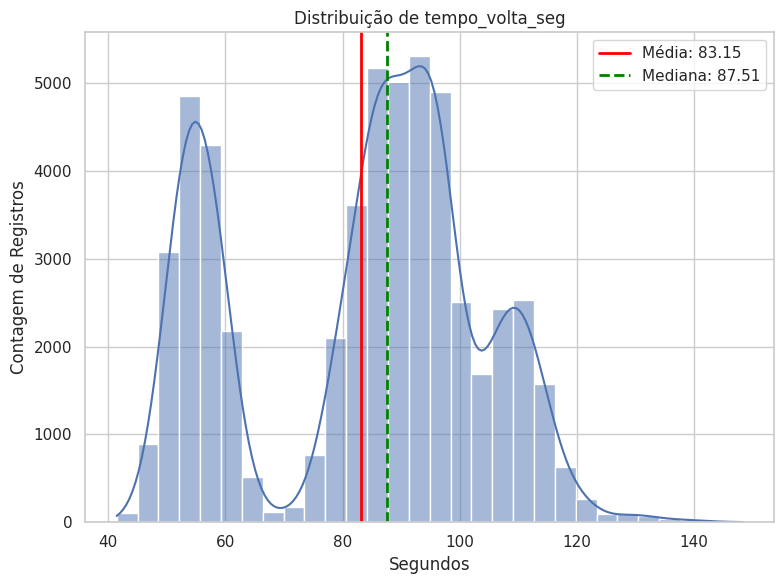

In [49]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("Segundos")        # lacuna: nome do eixo x, em linguagem simples
plt.ylabel("Contagem de Registros")            # lacuna: nome do eixo y, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

Célula 20 · Boxplot

O que esta célula faz: desenha o boxplot: a caixa é a faixa central (25% a 75%) e os pontos fora são candidatos a outlier. A linha vermelha marca a média.

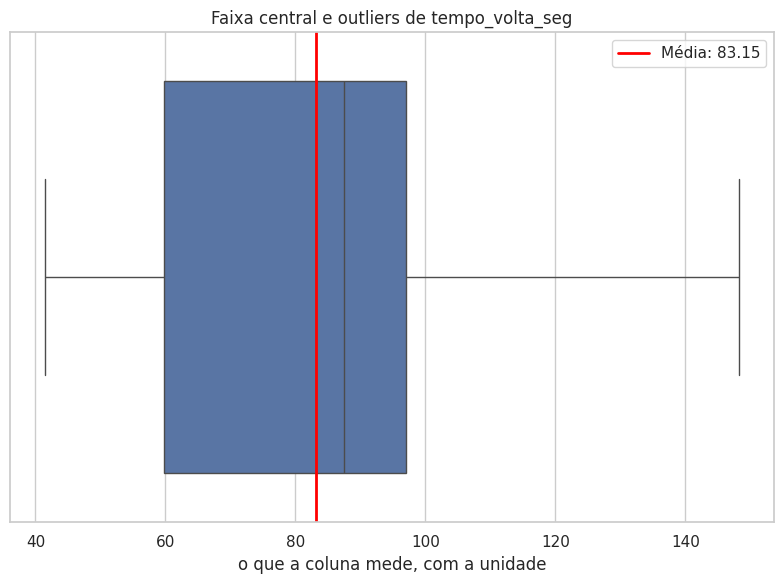

In [48]:
# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("o que a coluna mede, com a unidade")        # lacuna: nome do eixo x, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()